In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix

# Modelos requeridos por la guía
from sklearn.linear_model import LogisticRegression     # 1. Paramétrico
from sklearn.neighbors import KNeighborsClassifier        # 2. No Paramétrico
from sklearn.ensemble import RandomForestClassifier       # 3. Ensamble de Árboles
from sklearn.neural_network import MLPClassifier          # 4. Red Neuronal
from sklearn.svm import SVC                               # 5. SVM

import warnings
warnings.filterwarnings('ignore')

# Cargar conjuntos preprocesados
X_train = pd.read_csv('../data/processed/X_train.csv')
X_test = pd.read_csv('../data/processed/X_test.csv')
y_train = pd.read_csv('../data/processed/y_train.csv').values.ravel()
y_test = pd.read_csv('../data/processed/y_test.csv').values.ravel()

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

# Escalado de datos (Imprescindible para KNN, LogisticRegression, SVM y MLP)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train shape: (40000, 46), X_test shape: (10000, 46)


In [2]:
# Estrategia de Validación Cruzada (Stratified K-Fold con 5 Folds)
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Definición de las mallas de hiperparámetros para cada modelo
param_grids = {
    'Logistic Regression': {
        'model': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
        'scaled': True,
        'params': {
            'C': [0.01, 0.1, 1.0, 10.0],
            'solver': ['lbfgs', 'saga']
        }
    },
    'k-Nearest Neighbors': {
        'model': KNeighborsClassifier(),
        'scaled': True,
        'params': {
            'n_neighbors': [5, 9, 15],
            'weights': ['uniform', 'distance'],
            'metric': ['euclidean', 'manhattan']
        }
    },
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1),
        'scaled': False, # Árboles no requieren escalado obligatoriamente
        'params': {
            'n_estimators': [100, 200],
            'max_depth': [10, 20, None],
            'min_samples_split': [2, 5]
        }
    },
    'MLP Neural Network': {
        'model': MLPClassifier(max_iter=500, random_state=42),
        'scaled': True,
        'params': {
            'hidden_layer_sizes': [(64, 32), (100,)],
            'activation': ['relu', 'tanh'],
            'alpha': [0.0001, 0.001]
        }
    },
    'Support Vector Machine': {
        'model': SVC(class_weight='balanced', random_state=42),
        'scaled': True,
        'params': {
            'C': [0.1, 1.0, 10.0],
            'kernel': ['rbf', 'linear'],
            'gamma': ['scale', 'auto']
        }
    }
}

In [3]:
results = []
best_estimators = {}

for name, config in param_grids.items():
    print(f"\n==========================================")
    print(f" Entrenando y ajustando: {name}")
    print(f"==========================================")
    
    # Seleccionar datos escalados o no escalados según el modelo
    X_tr = X_train_scaled if config['scaled'] else X_train
    X_te = X_test_scaled if config['scaled'] else X_test
    
    # Búsqueda en Malla optimizando el Macro F1-Score
    grid_search = GridSearchCV(
        estimator=config['model'],
        param_grid=config['params'],
        cv=cv_strategy,
        scoring='f1_macro',
        n_jobs=-1,
        return_train_score=True
    )
    
    grid_search.fit(X_tr, y_train)
    best_model = grid_search.best_estimator_
    best_estimators[name] = best_model
    
    # Extraer métricas de Validación Cruzada del mejor hiperparámetro
    best_idx = grid_search.best_index_
    
    # Métricas de Train y Validación Cruzada
    cv_scores_val = [grid_search.cv_results_[f'split{i}_test_score'][best_idx] for i in range(5)]
    cv_scores_train = [grid_search.cv_results_[f'split{i}_train_score'][best_idx] for i in range(5)]
    
    val_mean = np.mean(cv_scores_val)
    val_std = np.std(cv_scores_val)
    train_mean = np.mean(cv_scores_train)
    
    # Evaluación final en el conjunto de TEST (Datos no vistos)
    y_pred_test = best_model.predict(X_te)
    test_f1 = f1_score(y_test, y_pred_test, average='macro')
    test_acc = accuracy_score(y_test, y_pred_test)
    
    # Intervalo de confianza (95%) aproximado para validación: ± 1.96 * std
    ci_val = 1.96 * val_std
    
    print(f"Mejores Hiperparámetros: {grid_search.best_params_}")
    print(f"F1-Macro Entrenam. : {train_mean:.4f}")
    print(f"F1-Macro Validación : {val_mean:.4f} ± {ci_val:.4f}")
    print(f"F1-Macro Test       : {test_f1:.4f}")
    
    results.append({
        'Modelo': name,
        'Hiperparámetros Óptimos': str(grid_search.best_params_),
        'Train F1-Macro': round(train_mean, 4),
        'Val F1-Macro (IC 95%)': f"{val_mean:.4f} ± {ci_val:.4f}",
        'Test F1-Macro': round(test_f1, 4),
        'Test Accuracy': round(test_acc, 4)
    })

# Convertir resultados a DataFrame
df_results = pd.DataFrame(results)
display(df_results)


 Entrenando y ajustando: Logistic Regression
Mejores Hiperparámetros: {'C': 1.0, 'solver': 'saga'}
F1-Macro Entrenam. : 0.8192
F1-Macro Validación : 0.8166 ± 0.0050
F1-Macro Test       : 0.8157

 Entrenando y ajustando: k-Nearest Neighbors
Mejores Hiperparámetros: {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}
F1-Macro Entrenam. : 1.0000
F1-Macro Validación : 0.7417 ± 0.0118
F1-Macro Test       : 0.7354

 Entrenando y ajustando: Random Forest
Mejores Hiperparámetros: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
F1-Macro Entrenam. : 0.9978
F1-Macro Validación : 0.8622 ± 0.0085
F1-Macro Test       : 0.8668

 Entrenando y ajustando: MLP Neural Network
Mejores Hiperparámetros: {'activation': 'tanh', 'alpha': 0.001, 'hidden_layer_sizes': (64, 32)}
F1-Macro Entrenam. : 0.9975
F1-Macro Validación : 0.8179 ± 0.0068
F1-Macro Test       : 0.8194

 Entrenando y ajustando: Support Vector Machine
Mejores Hiperparámetros: {'C': 10.0, 'gamma': 'scale', 'kernel':

,Modelo,Hiperparámetros Óptimos,Train F1-Macro,Val F1-Macro (IC 95%),Test F1-Macro,Test Accuracy
0,Logistic Regression,"{'C': 1.0, 'solver': 'saga'}",0.8192,0.8166 ± 0.0050,0.8157,0.9154
1,k-Nearest Neighbors,"{'metric': 'manhattan', 'n_neighbors': 5, 'wei...",1.0000,0.7417 ± 0.0118,0.7354,0.9204
2,Random Forest,"{'max_depth': None, 'min_samples_split': 5, 'n...",0.9978,0.8622 ± 0.0085,0.8668,0.9531
3,MLP Neural Network,"{'activation': 'tanh', 'alpha': 0.001, 'hidden...",0.9975,0.8179 ± 0.0068,0.8194,0.9360
4,Support Vector Machine,"{'C': 10.0, 'gamma': 'scale', 'kernel': 'rbf'}",0.9848,0.8247 ± 0.0067,0.8267,0.9378



El mejor modelo obtenido fue: Random Forest


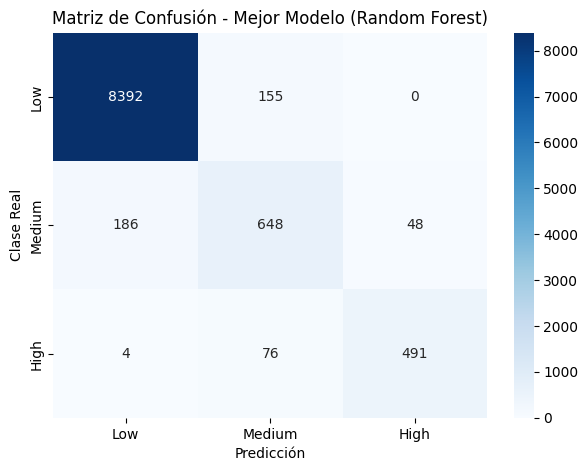

In [5]:
# Guardar tabla de resultados
df_results.to_csv('../data/processed/model_results_baseline.csv', index=False)

# Identificar el modelo con mejor F1-Macro en Test
best_model_name = df_results.sort_values(by='Test F1-Macro', ascending=False).iloc[0]['Modelo']
print(f"\nEl mejor modelo obtenido fue: {best_model_name}")

# Graficar la Matriz de Confusión del mejor modelo
X_te_best = X_test_scaled if param_grids[best_model_name]['scaled'] else X_test
y_pred_best = best_estimators[best_model_name].predict(X_te_best)

cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Low', 'Medium', 'High'], 
            yticklabels=['Low', 'Medium', 'High'])
plt.title(f'Matriz de Confusión - Mejor Modelo ({best_model_name})')
plt.xlabel('Predicción')
plt.ylabel('Clase Real')
plt.show()